# 06 — Classical forecasting models

## Purpose

We consolidate the completed **Ridge, Random Forest and LightGBM** model-development experiments. All three models use the same F0–F4 forecasting populations and three expanding chronological validation folds established in Notebook 05.

We examine how each model was configured and trained, verify the completed fold-level training records, and compare forecasting accuracy across the five feature families. The central feature comparison is **F3 versus F4 under the same model configuration**.

The original development archives are the experimental record; this notebook reconstructs and audits their results.

## 1. Forecasting protocol and model families

SOLETE photovoltaic power is predicted 15, 30 and 60 minutes ahead. F0 is historical PV and weather information; F1 adds Gregorian time, F2 solar geometry, F3 continuous lunar astronomy, and F4 five categorical Panchang groups.

Training uses three expanding chronological folds. The 60-minute training-label availability gap ensures all training targets would have been observed by the first validation forecast issue. Each validation fold is scored without retraining inside the fold. The pre-existing candidate grids are evaluated on the same samples.

| Model | Configurations per feature family and horizon | Fits across all 3 folds, 3 horizons and 5 families |
|---|---:|---:|
| Ridge regression | 5 | 225 |
| LightGBM | 8 | 360 |
| Random Forest | 8 | 360 |
| **Total** | **21** | **945** |

We use **unweighted mean fold MAE in kW** as the development candidate-ranking measure; RMSE is supplementary. All model evaluation here is over **all-hours** development validation, consistent with the frozen selection protocol. Daylight-only comparisons from the later dedicated forecasting experiment remain available in Notebooks 06–11.

In [1]:
from pathlib import Path
from io import BytesIO
from hashlib import sha256
from itertools import product
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((folder.resolve() for folder in (Path.cwd(), *Path.cwd().parents)
                     if (folder / 'src' / 'classical_models.py').is_file()
                     and (folder / 'results' / 'development_only').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from the SOLETE project directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.classical_models import (
    RIDGE_ALPHA_GRID, LIGHTGBM_CONFIGS, RANDOM_FOREST_CONFIGS,
    build_ridge_model, build_lightgbm_model, build_random_forest_model,
)
from src.forecasting_protocol import EXPECTED_CV_COUNTS_BY_HORIZON, MODEL_AVAILABILITY_GAP
from src.revised_classical_cv import evaluate_solete_cv_candidates

ARCHIVE = (PROJECT_ROOT / 'results' / 'development_only').resolve()
HORIZONS = (15, 30, 60)
FAMILIES = ('F0', 'F1', 'F2', 'F3', 'F4')
MODELS = ('Ridge', 'LightGBM', 'RandomForest')
GRIDS = {'Ridge': RIDGE_ALPHA_GRID, 'LightGBM': LIGHTGBM_CONFIGS,
         'RandomForest': RANDOM_FOREST_CONFIGS}
assert MODEL_AVAILABILITY_GAP == pd.Timedelta(minutes=60)
assert {name: len(grid) for name, grid in GRIDS.items()} == {
    'Ridge': 5, 'LightGBM': 8, 'RandomForest': 8}
print('Source protocol: 3 horizons × 5 feature families × 3 expanding folds')
display(pd.DataFrame([{'model': name, 'configurations': len(grid),
                       'archived_fold_fits': 3*3*5*len(grid)}
                      for name, grid in GRIDS.items()]))


Source protocol: 3 horizons × 5 feature families × 3 expanding folds


,model,configurations,archived_fold_fits
0,Ridge,5,225
1,LightGBM,8,360
2,RandomForest,8,360


## 2. Training and prediction procedure

For each architecture, horizon, feature family and candidate configuration, the original training runner constructs a **new unfitted estimator**, fits it on that fold's eligible training rows, predicts the subsequent validation rows and records MAE/RMSE. The candidate ranking uses the arithmetic mean of the three fold MAEs.

The tested implementation is `src.revised_classical_cv.evaluate_solete_cv_candidates`; it uses the folds from `src.forecasting_protocol`. Model factories in `src.classical_models` fix seeds and estimator parameters. Ridge includes its scaling pipeline inside the estimator, so any learned scaling is fitted on training rows only.

The same training call can reproduce a candidate's evaluation when supplied with one of Notebook 05's aligned feature matrices, target series, and issue/valid-time series:

```python
fold_scores, candidate_ranking = evaluate_solete_cv_candidates(
    X=X, y=y, issue_time=issue_time, valid_time=valid_time,
    horizon_minutes=15,
    configurations=LIGHTGBM_CONFIGS,
    model_factory=build_lightgbm_model,
)
```

The following check constructs all three model types from the frozen definitions and displays representative parameter settings.

In [2]:
factories = {
    'Ridge': lambda: build_ridge_model(float(RIDGE_ALPHA_GRID[0])),
    'LightGBM': lambda: build_lightgbm_model(dict(LIGHTGBM_CONFIGS[0])),
    'RandomForest': lambda: build_random_forest_model(dict(RANDOM_FOREST_CONFIGS[0])),
}
model_specs = []
for name, make_model in factories.items():
    estimator = make_model()
    model_specs.append({
        'model': name, 'estimator': type(estimator).__name__,
        'first_candidate': json.dumps(dict(GRIDS[name][0]) if name != 'Ridge'
                                      else {'alpha': float(RIDGE_ALPHA_GRID[0])}, sort_keys=True),
        'configurations': len(GRIDS[name]),
    })
display(pd.DataFrame(model_specs))
assert len(model_specs) == 3


,model,estimator,first_candidate,configurations
0,Ridge,Pipeline,"{""alpha"": 0.01}",5
1,LightGBM,LGBMRegressor,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""...",8
2,RandomForest,RandomForestRegressor,"{""max_depth"": null, ""max_features"": 0.5, ""min_...",8


## 3. Verify Ridge and LightGBM experiment archives

The archived CSV results contain each completed candidate's exact training/validation row counts and out-of-fold errors. We verify the saved SHA-256 checksums and exact table lengths against the original manifests before using the metrics.

In [3]:
def development_file(relative_path):
    file = (ARCHIVE / relative_path).resolve()
    assert file.is_relative_to(ARCHIVE), relative_path
    if not file.is_file():
        raise FileNotFoundError(file)
    return file


def read_manifest_archive(subdir, prefix, expected_rows):
    relative_dir = f'revised_classical_cv_v1/{subdir}'
    manifest = json.loads(development_file(f'{relative_dir}/manifest.json').read_text())
    assert isinstance(manifest.get('source_sha256'), str) and len(manifest['source_sha256']) == 64
    assert manifest.get('terminal_test_evaluated') is not True
    tables = {}
    for name, expected in expected_rows.items():
        filename = f'{prefix}_{name}.csv'
        raw = development_file(f'{relative_dir}/{filename}').read_bytes()
        record = manifest['files'][filename]
        assert sha256(raw).hexdigest() == record['sha256']
        table = pd.read_csv(BytesIO(raw))
        assert len(table) == expected == record['rows']
        tables[name] = table
    return tables

ridge = read_manifest_archive('ridge', 'ridge', {
    'fold_scores': 225, 'candidate_rankings': 75, 'selected': 15, 'runtimes': 15})
lightgbm = read_manifest_archive('lightgbm', 'lightgbm', {
    'fold_scores': 360, 'candidate_rankings': 120, 'selected': 15, 'runtimes': 15})


def standardize_csv(fold_scores, model):
    required = {'horizon_minutes','feature_family','config_index','configuration',
                'fold','train_rows','validation_rows','validation_mae','validation_rmse'}
    assert required.issubset(fold_scores.columns)
    frame = fold_scores.copy()
    frame['model'] = model
    frame['candidate_id'] = model + '_C' + (frame['config_index'].astype(int)+1).astype(str)
    frame['configuration_json'] = frame['configuration'].map(
        lambda x: json.dumps(json.loads(x), sort_keys=True))
    return frame.rename(columns={'validation_mae':'validation_mae_kw',
                                 'validation_rmse':'validation_rmse_kw'})

ridge_cv = standardize_csv(ridge['fold_scores'], 'Ridge')
lgb_cv = standardize_csv(lightgbm['fold_scores'], 'LightGBM')
assert (len(ridge_cv), len(lgb_cv)) == (225, 360)
print('Manifest-verified classical CSV fold scores:', len(ridge_cv) + len(lgb_cv))


Manifest-verified classical CSV fold scores: 585


## 4. Verify Random Forest checkpoints

Random Forest used resumable JSON checkpoints. Each file records all eight configurations and three folds for a single horizon–feature-family combination. We verify every checkpoint's source fingerprint and full candidate-by-fold coverage.

In [4]:
rf_sources = ('src/classical_models.py', 'src/revised_classical_cv.py',
              'src/forecasting_protocol.py', 'src/revised_rf_checkpoint.py')
rf_digest = sha256(b''.join((PROJECT_ROOT / f).read_bytes() for f in rf_sources)).hexdigest()
rf_records = []
for horizon, family in product(HORIZONS, FAMILIES):
    archive_file = development_file(f'revised_classical_cv_v1/random_forest/h{horizon}_{family}.json')
    archive = json.loads(archive_file.read_text())
    assert archive['schema_version'] == 1
    assert archive['model'] == 'RandomForestRegressor'
    assert (archive['horizon_minutes'], archive['feature_family']) == (horizon, family)
    assert archive['source_sha256'] == rf_digest
    assert isinstance(archive['signature_sha256'], str) and len(archive['signature_sha256']) == 64
    assert len(archive['candidate_configurations']) == 8
    assert len(archive['fits']) == 24
    assert {(int(f['config_index']),int(f['fold'])) for f in archive['fits']} == set(product(range(8),(1,2,3)))
    for fit in archive['fits']:
        config_index = int(fit['config_index'])
        rf_records.append({
            'model': 'RandomForest', 'horizon_minutes': horizon, 'feature_family': family,
            'config_index': config_index, 'candidate_id': f'RandomForest_C{config_index+1}',
            'configuration_json': json.dumps(archive['candidate_configurations'][config_index],sort_keys=True),
            'fold': int(fit['fold']), 'train_rows':int(fit['train_rows']),
            'validation_rows': int(fit['validation_rows']),
            'validation_mae_kw': float(fit['validation_mae']),
            'validation_rmse_kw':float(fit['validation_rmse']),
        })
rf_cv = pd.DataFrame(rf_records)
assert len(rf_cv) == 360
print('Source-verified Random Forest fold scores:', len(rf_cv))


Source-verified Random Forest fold scores: 360


## 5. Check shared training/validation populations

All 945 evaluations must use the exact same three fold populations at a given forecast horizon. Each candidate must have all three folds and both finite error metrics.

In [5]:
COLS = ('model','horizon_minutes','feature_family','config_index','candidate_id',
        'configuration_json','fold','train_rows','validation_rows','validation_mae_kw',
        'validation_rmse_kw')
classical_cv = pd.concat([ridge_cv[list(COLS)],lgb_cv[list(COLS)],rf_cv[list(COLS)]],ignore_index=True)
keys = ['model','horizon_minutes','feature_family','config_index','fold']
expected = set().union(*(set(product((model,),HORIZONS,FAMILIES,range(len(GRIDS[model])),(1,2,3)))
                         for model in MODELS))
actual = set(classical_cv[keys].itertuples(index=False,name=None))
assert len(classical_cv) == len(expected) == 945
assert actual == expected
assert not classical_cv.duplicated(keys).any()
assert np.isfinite(classical_cv[['validation_mae_kw','validation_rmse_kw']].to_numpy(dtype=float)).all()
assert (classical_cv['validation_rmse_kw']+1e-8 >= classical_cv['validation_mae_kw']).all()
for row in classical_cv.itertuples(index=False):
    assert (row.train_rows,row.validation_rows) == EXPECTED_CV_COUNTS_BY_HORIZON[row.horizon_minutes][row.fold-1]
assert (classical_cv.groupby(keys[:-1])['fold'].nunique()==3).all()
print('CLASSICAL DEVELOPMENT TRAINING ARCHIVE: 945/945 VERIFIED')
display(classical_cv.groupby('model').agg(fold_fits=('fold','size'),
                                         configurations=('configuration_json','nunique')).reset_index())


CLASSICAL DEVELOPMENT TRAINING ARCHIVE: 945/945 VERIFIED


,model,fold_fits,configurations
0,LightGBM,360,8
1,RandomForest,360,8
2,Ridge,225,5


## 6. Rank classical candidates across F0–F4

For each model, horizon and feature family, the winning configuration minimizes the unweighted mean of its three fold MAEs. The accompanying table shows the five-feature-family progression for all three architectures.

In [6]:
candidate_keys = ['model','horizon_minutes','feature_family','config_index',
                  'candidate_id','configuration_json']
classical_candidates = (classical_cv.groupby(candidate_keys,as_index=False)
    .agg(cv_mae_kw=('validation_mae_kw','mean'),cv_rmse_kw=('validation_rmse_kw','mean'),
         fold_mae_std_kw=('validation_mae_kw','std'),folds=('fold','nunique')))
assert len(classical_candidates) == (5+8+8)*3*5 == 315
assert classical_candidates['folds'].eq(3).all()
classical_candidates = classical_candidates.sort_values(
    ['model','horizon_minutes','feature_family','cv_mae_kw','config_index'],kind='stable')
classical_winners = classical_candidates.drop_duplicates(
    ['model','horizon_minutes','feature_family']).reset_index(drop=True)
assert len(classical_winners) == 3*3*5 == 45
progression = classical_winners.pivot(index=['model','horizon_minutes'],columns='feature_family',
                                    values='cv_mae_kw').reindex(columns=list(FAMILIES))
print('Lowest mean three-fold development MAE (kW) per model / horizon / family:')
display(progression.round(6))


Lowest mean three-fold development MAE (kW) per model / horizon / family:


feature_family                      F0        F1        F2        F3        F4
model        horizon_minutes                                                  
LightGBM     15               0.186805  0.177400  0.178696  0.180784  0.179828
             30               0.243146  0.220946  0.219329  0.221195  0.222238
             60               0.326559  0.287611  0.280951  0.285970  0.284991
RandomForest 15               0.182358  0.179036  0.177618  0.179622  0.179598
             30               0.237948  0.225092  0.226551  0.229083  0.227636
             60               0.322818  0.286863  0.291135  0.295827  0.294765
Ridge        15               0.223734  0.306610  0.306517  0.264452  0.303371
             30               0.301027  0.442702  0.443909  0.360826  0.444886
             60               0.421255  0.669405  0.678198  0.508959  0.684748

## 7. Matched-configuration F3–F4 comparison

A fair feature-ablation comparison holds the architecture, horizon and hyperparameter configuration fixed. For each of the 63 classical configurations across horizons we compare `MAE(F3) − MAE(F4)`; **positive means F4 has lower error**. We also report family-wise tuned results separately because their hyperparameters may differ.

In [7]:
comparison_keys = ['model','horizon_minutes','config_index']
f3 = classical_candidates.query("feature_family == 'F3'")
f4 = classical_candidates.query("feature_family == 'F4'")
classical_pairs = f3[comparison_keys+['cv_mae_kw']].merge(
    f4[comparison_keys+['cv_mae_kw']],on=comparison_keys,suffixes=('_F3','_F4'),validate='one_to_one')
classical_pairs['f4_gain_kw'] = classical_pairs['cv_mae_kw_F3'] - classical_pairs['cv_mae_kw_F4']
assert len(classical_pairs) == (5+8+8)*3 == 63
classical_matched = classical_pairs.groupby(['model','horizon_minutes'],as_index=False).agg(
    matched_configs=('config_index','size'),
    mean_gain_kw=('f4_gain_kw','mean'),
    configs_favoring_f4=('f4_gain_kw',lambda x:int((x>0).sum())))
print('Matched F3–F4 comparisons (positive gain favors F4):')
display(classical_matched.round(6))

w3 = classical_winners.query("feature_family == 'F3'")[['model','horizon_minutes','cv_mae_kw']]
w4 = classical_winners.query("feature_family == 'F4'")[['model','horizon_minutes','cv_mae_kw']]
classical_tuned = w3.merge(w4,on=['model','horizon_minutes'],suffixes=('_F3','_F4'),validate='one_to_one')
classical_tuned['f4_gain_kw'] = classical_tuned['cv_mae_kw_F3'] - classical_tuned['cv_mae_kw_F4']
print('Separately tuned family-best F3–F4 comparison:')
display(classical_tuned.round(6))


Matched F3–F4 comparisons (positive gain favors F4):


,model,horizon_minutes,matched_configs,mean_gain_kw,configs_favoring_f4
0,LightGBM,15,8,-0.000308,4
1,LightGBM,30,8,-0.002039,2
2,LightGBM,60,8,0.002066,7
3,RandomForest,15,8,0.000250,5
4,RandomForest,30,8,0.000183,5
5,RandomForest,60,8,-0.000060,2
6,Ridge,15,5,-0.084066,0
7,Ridge,30,5,-0.133794,0
8,Ridge,60,5,-0.209565,0


Separately tuned family-best F3–F4 comparison:


,model,horizon_minutes,cv_mae_kw_F3,cv_mae_kw_F4,f4_gain_kw
0,LightGBM,15,0.180784,0.179828,0.000956
1,LightGBM,30,0.221195,0.222238,-0.001043
2,LightGBM,60,0.285970,0.284991,0.000979
3,RandomForest,15,0.179622,0.179598,0.000024
4,RandomForest,30,0.229083,0.227636,0.001448
5,RandomForest,60,0.295827,0.294765,0.001062
6,Ridge,15,0.264452,0.303371,-0.038919
7,Ridge,30,0.360826,0.444886,-0.084059
8,Ridge,60,0.508959,0.684748,-0.175790


## 8. Visualize the F0–F4 progression

The following plot uses the best three-fold development configuration within each feature family. The matched-configuration F3–F4 estimates above are the better-controlled feature-ablation measure.

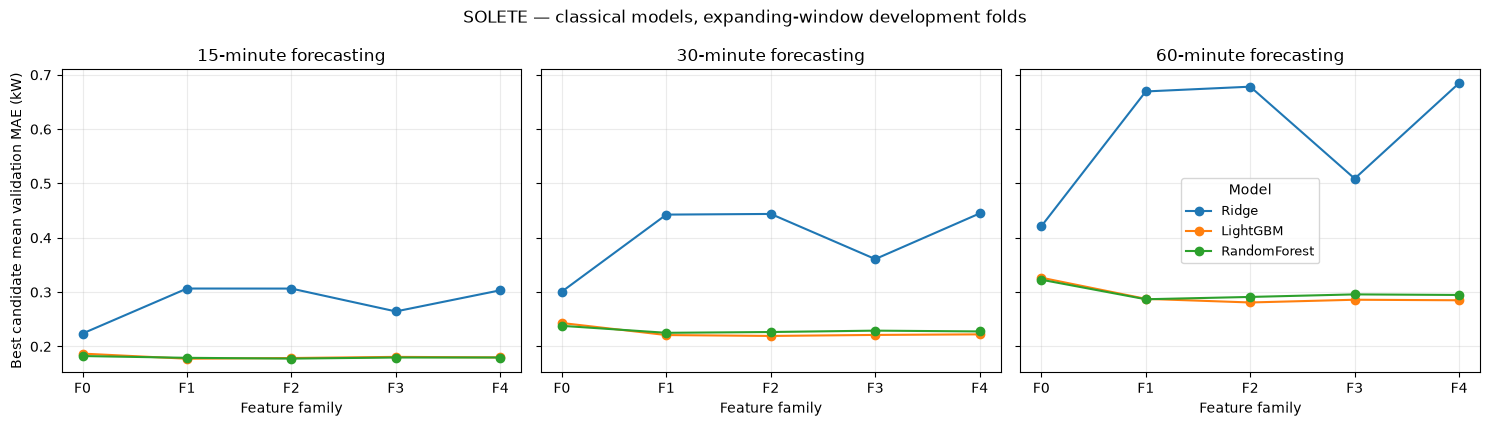

In [8]:
fig, axes = plt.subplots(1,3,figsize=(15,4.3),sharey=True)
for ax, horizon in zip(axes,HORIZONS):
    for model in MODELS:
        values = progression.loc[(model,horizon),list(FAMILIES)].to_numpy(dtype=float)
        ax.plot(FAMILIES,values,marker='o',label=model)
    ax.set_title(f'{horizon}-minute forecasting')
    ax.set_xlabel('Feature family')
    ax.grid(alpha=.25)
axes[0].set_ylabel('Best candidate mean validation MAE (kW)')
axes[-1].legend(title='Model',fontsize=9)
fig.suptitle('SOLETE — classical models, expanding-window development folds')
fig.tight_layout()
plt.show()


## 9. Preserve the consolidated classical results

We save the verified fold scores, candidate rankings, F0–F4 family winners and matched F3–F4 effects. These results will be combined with the neural archive in the subsequent cross-architecture analysis.

In [9]:
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'model_architectures'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
artifacts = {
    'classical_fold_scores.csv': classical_cv,
    'classical_candidate_rankings.csv': classical_candidates,
    'classical_family_winners.csv': classical_winners,
    'classical_matched_f3_f4.csv': classical_pairs,
    'classical_tuned_f3_f4.csv': classical_tuned,
}
for name, frame in artifacts.items():
    location = OUTPUT_DIR / name
    frame.to_csv(location,index=False,float_format='%.12g')
    saved = pd.read_csv(location)
    assert len(saved)==len(frame)
    print(name,':',len(saved),'rows')
assert len(classical_cv)==945 and len(classical_candidates)==315
assert len(classical_winners)==45 and len(classical_pairs)==63
print('NOTEBOOK 12: CLASSICAL MODEL ARCHIVE CHECKS PASSED')


classical_fold_scores.csv : 945 rows
classical_candidate_rankings.csv : 315 rows
classical_family_winners.csv : 45 rows
classical_matched_f3_f4.csv : 63 rows
classical_tuned_f3_f4.csv : 9 rows
NOTEBOOK 12: CLASSICAL MODEL ARCHIVE CHECKS PASSED


## What we learned

The revised classical development record contains **945 completed fold evaluations** covering Ridge, LightGBM and Random Forest. All three architectures were evaluated on identical chronological folds with the same F0–F4 feature hierarchy.

The full feature-family progression identifies the relative contribution of conventional time, solar, continuous lunar and categorical Panchang representations. The matched F3–F4 comparisons isolate the feature addition under unchanged hyperparameters. These are development-fold model-training results; the separate SOLETE/PVOD retrospective evaluations remain documented in Notebooks 09 and 10.